In [ ]:
pip install pythonnet pandas numpy

In [5]:
from pythonnet import load
load("coreclr")

import clr
import sys
import os
import pandas as pd
import numpy as np
import time

dwsim_path = r"C:\Users\HomePC\Downloads\DWSIM"
sim_path = r"C:\Users\HomePC\Downloads\LPG_Recovery_Base.dwxmz"
csv_path = r"C:\Users\HomePC\LPG_Optimization_Project\data\LPG_Energy_Data.csv"

os.chdir(dwsim_path)
sys.path.append(dwsim_path)

clr.AddReference("CapeOpen")
clr.AddReference("DWSIM.Automation")
clr.AddReference("DWSIM.Interfaces")
clr.AddReference("DWSIM.GlobalSettings")
clr.AddReference("DWSIM.SharedClasses")
clr.AddReference("DWSIM.Thermodynamics")

from DWSIM.Automation import Automation3

interf = Automation3()
sim = interf.LoadFlowsheet(sim_path)

cooler = sim.GetFlowsheetSimulationObject("CL-1").GetAsObject()
compressor = sim.GetFlowsheetSimulationObject("C-1").GetAsObject()

scol1 = sim.GetFlowsheetSimulationObject("SCOL-1").GetAsObject()
scol2 = sim.GetFlowsheetSimulationObject("SCOL-2").GetAsObject()

comp_power_stream = sim.GetFlowsheetSimulationObject("E1").GetAsObject()
cooler_duty_stream = sim.GetFlowsheetSimulationObject("E2").GetAsObject()

deeth_cond = sim.GetFlowsheetSimulationObject("Q_Condenser").GetAsObject()
deeth_reb = sim.GetFlowsheetSimulationObject("Q_Reboiler").GetAsObject()

debut_cond = sim.GetFlowsheetSimulationObject("E5").GetAsObject()
debut_reb = sim.GetFlowsheetSimulationObject("E6").GetAsObject()

lpg_stream = sim.GetFlowsheetSimulationObject("Pure_LPG").GetAsObject()

cooler_temps = np.linspace(15, 45, 50)
compressor_pressures = np.linspace(15, 35, 50)

data_records = []
total_runs = len(cooler_temps) * len(compressor_pressures)
current_run = 0
start_time = time.time()

for temp in cooler_temps:
    for pres in compressor_pressures:
        current_run += 1
        
        cooler.OutletTemperature = float(temp + 273.15)
        compressor.POut = float(pres * 100000.0)
        
        errors = interf.CalculateFlowsheet2(sim)
        
        status = "Success"
        w_comp, q_cool = 0.0, 0.0
        q_deeth_c, q_deeth_r = 0.0, 0.0
        q_debut_c, q_debut_r = 0.0, 0.0
        total_col_kw, total_plant_kw, sec_kwh_kg = 0.0, 0.0, 0.0
        lpg_kgh = 0.0
        
        if errors is not None and errors.Count > 0:
            status = f"Failed (Global): {errors[0].Message}"
        elif scol1.ErrorMessage and str(scol1.ErrorMessage).strip() != "":
            status = f"Failed (SCOL-1): {scol1.ErrorMessage}"
        elif scol2.ErrorMessage and str(scol2.ErrorMessage).strip() != "":
            status = f"Failed (SCOL-2): {scol2.ErrorMessage}"
        else:
            w_comp = abs(float(comp_power_stream.EnergyFlow))
            q_cool = abs(float(cooler_duty_stream.EnergyFlow))
            q_deeth_c = abs(float(deeth_cond.EnergyFlow))
            q_deeth_r = abs(float(deeth_reb.EnergyFlow))
            q_debut_c = abs(float(debut_cond.EnergyFlow))
            q_debut_r = abs(float(debut_reb.EnergyFlow))
            lpg_kgh = float(lpg_stream.GetMassFlow()) * 3600.0
            
            if lpg_kgh < 0.1 or np.isnan(q_debut_c) or np.isnan(q_deeth_c):
                status = "Invalid Thermodynamics"
            else:
                total_col_kw = q_deeth_c + q_deeth_r + q_debut_c + q_debut_r
                total_plant_kw = w_comp + q_cool + total_col_kw
                # Specific Energy Consumption 
                sec_kwh_kg = total_plant_kw / lpg_kgh
                
        data_records.append({
            "Cooler_Outlet_Temperature_C": round(float(temp), 4),
            "Compressor_Outlet_Pressure_bar": round(float(pres), 4),
            "Compressor_Power_kW": w_comp,
            "Cooler_Duty_kW": q_cool,
            "Deethanizer_Condenser_kW": q_deeth_c,
            "Deethanizer_Reboiler_kW": q_deeth_r,
            "Debutanizer_Condenser_kW": q_debut_c,
            "Debutanizer_Reboiler_kW": q_debut_r,
            "Total_Column_Energy_kW": total_col_kw,
            "Total_Plant_Energy_kW": total_plant_kw,
            "Pure_LPG_Recovery_kgh": lpg_kgh,
            "Specific_Energy_kWh_per_kg": sec_kwh_kg,
            "Solve_Status": status
        })
        
        if current_run % 250 == 0 or current_run == 1:
            elapsed = time.time() - start_time
            print(f"  -> [{current_run}/{total_runs}] ({elapsed:.1f}s) | T={temp:.1f}°C, P={pres:.1f}bar | Plant={total_plant_kw:.1f}kW | LPG={lpg_kgh:.1f}kg/h | SEC={sec_kwh_kg:.3f}kWh/kg | {status}")

df = pd.DataFrame(data_records)
df.to_csv(csv_path, index=False)

df_clean = df[df["Solve_Status"] == "Success"].copy()
clean_csv_path = r"C:\Users\HomePC\LPG_Optimization_Project\data\LPG_Energy_Data_Clean.csv"
df_clean.to_csv(clean_csv_path, index=False)

print(f"Saved {len(df)} total rows ({len(df_clean)} valid rows)")
display(df_clean.head())

  -> [1/2500] (0.1s) | T=15.0°C, P=15.0bar | Plant=83.1kW | LPG=44.3kg/h | SEC=1.878kWh/kg | Success
  -> [250/2500] (27.8s) | T=17.4°C, P=35.0bar | Plant=225.0kW | LPG=122.9kg/h | SEC=1.831kWh/kg | Success
  -> [500/2500] (58.6s) | T=20.5°C, P=35.0bar | Plant=211.3kW | LPG=110.2kg/h | SEC=1.918kWh/kg | Success
  -> [750/2500] (85.6s) | T=23.6°C, P=35.0bar | Plant=198.0kW | LPG=97.5kg/h | SEC=2.030kWh/kg | Success
  -> [1000/2500] (112.6s) | T=26.6°C, P=35.0bar | Plant=184.9kW | LPG=85.0kg/h | SEC=2.176kWh/kg | Success
  -> [1250/2500] (140.8s) | T=29.7°C, P=35.0bar | Plant=172.3kW | LPG=72.7kg/h | SEC=2.369kWh/kg | Success
  -> [1500/2500] (168.4s) | T=32.8°C, P=35.0bar | Plant=160.1kW | LPG=60.9kg/h | SEC=2.628kWh/kg | Success
  -> [1750/2500] (196.9s) | T=35.8°C, P=35.0bar | Plant=148.4kW | LPG=49.6kg/h | SEC=2.993kWh/kg | Success
  -> [2000/2500] (222.2s) | T=38.9°C, P=35.0bar | Plant=137.4kW | LPG=38.9kg/h | SEC=3.534kWh/kg | Success
  -> [2250/2500] (246.4s) | T=41.9°C, P=35.0bar

,Cooler_Outlet_Temperature_C,Compressor_Outlet_Pressure_bar,Compressor_Power_kW,Cooler_Duty_kW,Deethanizer_Condenser_kW,Deethanizer_Reboiler_kW,Debutanizer_Condenser_kW,Debutanizer_Reboiler_kW,Total_Column_Energy_kW,Total_Plant_Energy_kW,Pure_LPG_Recovery_kgh,Specific_Energy_kWh_per_kg,Solve_Status
0,15.0,15.0000,14.157281,37.757696,3.017903,0.449348,9.020556,18.697929,31.185736,83.100713,44.251140,1.877934,Success
1,15.0,15.4082,15.121452,39.304747,3.237999,0.506498,9.529522,19.543414,32.817434,87.243633,46.723192,1.867245,Success
2,15.0,15.8163,16.069461,40.825990,3.463586,0.567853,10.036386,20.377216,34.445040,91.340492,49.182459,1.857176,Success
3,15.0,16.2245,16.993849,42.314136,3.694488,0.633391,10.540489,21.198967,36.067335,95.375320,51.625815,1.847435,Success
4,15.0,16.6327,17.898458,43.773208,3.930536,0.703082,11.041245,22.008361,37.683225,99.354891,54.050484,1.838187,Success


OPTIMAL SPECIFIC ENERGY SWEET SPOT
Cooler Outlet Temp       : 15.00 °C
Compressor Outlet Press  : 26.84 bar
Minimum Specific Energy  : 1.7470 kWh / kg LPG
Pure LPG Recovery at Opt : 105.16 kg/h
Total Plant Energy at Opt: 183.72 kW



,min,mean,std,max
Cooler_Outlet_Temperature_C,15.000000,28.933120,8.437784,45.000000
Compressor_Outlet_Pressure_bar,15.000000,25.657021,5.688152,35.000000
Compressor_Power_kW,14.157281,33.312096,8.953845,46.454523
Cooler_Duty_kW,17.537680,52.778258,15.957194,90.502218
Deethanizer_Condenser_kW,0.017734,4.814986,3.826403,17.983733
Deethanizer_Reboiler_kW,0.000656,0.935805,1.291828,7.088010
Debutanizer_Condenser_kW,0.042034,9.661159,6.614480,27.588375
Debutanizer_Reboiler_kW,0.109635,18.434866,11.230866,46.521104
Total_Column_Energy_kW,0.177632,33.846815,22.708570,99.181222
Total_Plant_Energy_kW,32.309248,119.937169,44.040566,236.137964


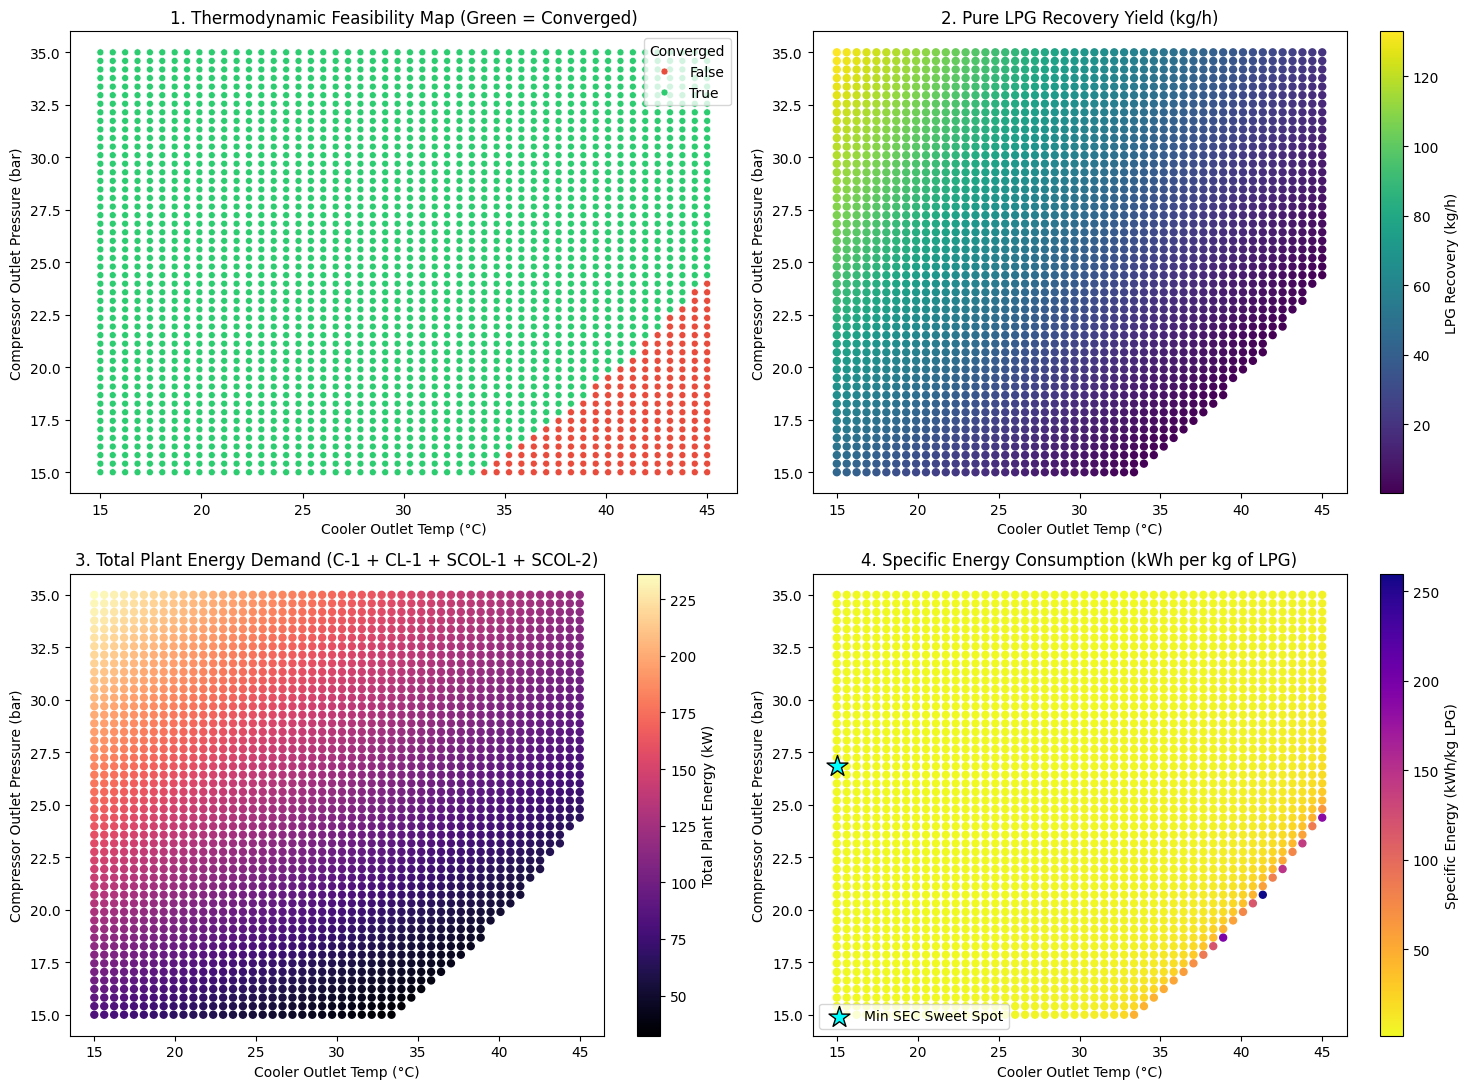

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = r"C:\Users\HomePC\LPG_Optimization_Project\data\LPG_Energy_Data.csv"
clean_csv_path = r"C:\Users\HomePC\LPG_Optimization_Project\data\LPG_Energy_Data_Clean.csv"

df = pd.read_csv(csv_path)
df_clean = pd.read_csv(clean_csv_path)

# Finding the absolute most energy-efficient operating point (Minimum Specific Energy)
best_idx = df_clean["Specific_Energy_kWh_per_kg"].idxmin()
best_row = df_clean.loc[best_idx]

print("OPTIMAL SPECIFIC ENERGY SWEET SPOT")
print(f"Cooler Outlet Temp       : {best_row['Cooler_Outlet_Temperature_C']:.2f} °C")
print(f"Compressor Outlet Press  : {best_row['Compressor_Outlet_Pressure_bar']:.2f} bar")
print(f"Minimum Specific Energy  : {best_row['Specific_Energy_kWh_per_kg']:.4f} kWh / kg LPG")
print(f"Pure LPG Recovery at Opt : {best_row['Pure_LPG_Recovery_kgh']:.2f} kg/h")
print(f"Total Plant Energy at Opt: {best_row['Total_Plant_Energy_kW']:.2f} kW\n")

# Summary table of all plant variables
display(df_clean.describe().T[["min", "mean", "std", "max"]])

# 2. Ploting 4-Panel Plant Analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: Thermodynamic Feasibility Map
sns.scatterplot(
    data=df, x="Cooler_Outlet_Temperature_C", y="Compressor_Outlet_Pressure_bar",
    hue=(df["Solve_Status"] == "Success"), palette={True: "#2ecc71", False: "#e74c3c"},
    s=25, ax=axes[0, 0]
)
axes[0, 0].set_title("1. Thermodynamic Feasibility Map (Green = Converged)")
axes[0, 0].set_xlabel("Cooler Outlet Temp (°C)")
axes[0, 0].set_ylabel("Compressor Outlet Pressure (bar)")
axes[0, 0].legend(title="Converged")

# Panel 2: Pure LPG Recovery (kg/h)
sc1 = axes[0, 1].scatter(
    df_clean["Cooler_Outlet_Temperature_C"], df_clean["Compressor_Outlet_Pressure_bar"],
    c=df_clean["Pure_LPG_Recovery_kgh"], cmap="viridis", s=25
)
plt.colorbar(sc1, ax=axes[0, 1], label="LPG Recovery (kg/h)")
axes[0, 1].set_title("2. Pure LPG Recovery Yield (kg/h)")
axes[0, 1].set_xlabel("Cooler Outlet Temp (°C)")
axes[0, 1].set_ylabel("Compressor Outlet Pressure (bar)")

# Panel 3: Total Plant Energy (Compressor + Cooler + Both Columns)
sc2 = axes[1, 0].scatter(
    df_clean["Cooler_Outlet_Temperature_C"], df_clean["Compressor_Outlet_Pressure_bar"],
    c=df_clean["Total_Plant_Energy_kW"], cmap="magma", s=25
)
plt.colorbar(sc2, ax=axes[1, 0], label="Total Plant Energy (kW)")
axes[1, 0].set_title("3. Total Plant Energy Demand (C-1 + CL-1 + SCOL-1 + SCOL-2)")
axes[1, 0].set_xlabel("Cooler Outlet Temp (°C)")
axes[1, 0].set_ylabel("Compressor Outlet Pressure (bar)")

# Panel 4: Specific Energy Consumption (kWh / kg LPG) + Optimal Sweet Spot Star
sc3 = axes[1, 1].scatter(
    df_clean["Cooler_Outlet_Temperature_C"], df_clean["Compressor_Outlet_Pressure_bar"],
    c=df_clean["Specific_Energy_kWh_per_kg"], cmap="plasma_r", s=25
)
axes[1, 1].scatter(
    best_row["Cooler_Outlet_Temperature_C"], best_row["Compressor_Outlet_Pressure_bar"],
    color="cyan", edgecolors="black", marker="*", s=250, label="Min SEC Sweet Spot"
)
plt.colorbar(sc3, ax=axes[1, 1], label="Specific Energy (kWh/kg LPG)")
axes[1, 1].set_title("4. Specific Energy Consumption (kWh per kg of LPG)")
axes[1, 1].set_xlabel("Cooler Outlet Temp (°C)")
axes[1, 1].set_ylabel("Compressor Outlet Pressure (bar)")
axes[1, 1].legend(loc="lower left")

plt.tight_layout()
plt.show()